# TKG4 2021: SWE and bulk snow density

Compare the existing HRRR-AK-forced SNOWPACK run, original snow pit sheet, and radar within 500 m of TKG4. This notebook is standalone: run top to bottom with **JIF snow modeling**. Source data are read only; the snow-depth notebook is not executed.

Start with **total-column SWE** and **effective bulk density**, calculated as `1000 × SWE (m w.e.) / depth (m)` in kg/m³. Model density includes any older snow/firn. Pit and radar describe seasonal snow, so these are descriptive comparisons rather than equivalent-column validation. Depth-only subtraction is deliberately not used to derive adjusted SWE or density: that would also require the mass of older firn.

In [1]:
from pathlib import Path
import csv
import json
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Circle
from pyproj import Transformer
from IPython.display import display

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar/01_explore_radar_2021.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from jif_snow_modeling/ or a directory inside it.')
PIT_PATH = Path('/hdd/snow_hydrology/JIF_radar/snowpits/2021_Mass_Balance_TKG4.csv')
RADAR_PATH = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
REFERENCE_NOTEBOOKS = sorted((REPO_ROOT / 'sites/tkg4').glob('3_read_snowpack_output*.ipynb'))
MODEL_PATHS_EXTRA = []  # Optional additional SMET paths.
START, END = pd.Timestamp('2020-10-01'), pd.Timestamp('2021-10-01')
# Paper dates supplied by the user; exact acquisition time/timezone not provided.
RADAR_DATE = pd.Timestamp('2021-07-13')
PAPER_GT_DATE = pd.Timestamp('2021-07-13')
RADAR_START, RADAR_END = RADAR_DATE, RADAR_DATE + pd.Timedelta(days=1)
RADAR_RADIUS_M = 500
RADAR_EPSG = 32608  # Provisional datum assumption.
SAVE_OUTPUTS = False
OUTPUT_DIR = REPO_ROOT / 'sites/tkg4/output/swe_density_2021'
print('Python:', sys.executable)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.2})
import seaborn as sns
from matplotlib.lines import Line2D
FIGURE_DIR = REPO_ROOT / 'sites/tkg4/figures'
SAVE_FIGURES = True
MODEL_COLOR, PIT_COLOR, RADAR_COLOR = 'tab:blue', 'tab:red', 'tab:green'


Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python


## Pit measurements and observation dates

The archived pit was dug on **7 July** and sampled for density on **8 July**. The user-supplied paper table dates both GT and GPR to **13 July**; retain that discrepancy rather than reassigning the archived measurement. Use 8 July for the pit SWE/density marker, and 13 July for radar. Acquisition times/timezones are unspecified; model comparisons use UTC daily summaries.

The sheet reports adjusted seasonal SWE of **201.43 cm w.e.** for **378 cm** of seasonal snow. Their ratio gives an effective bulk density. This is distinct from a simple average of profile samples or the sheet's rounded average density. The density profile extends into firn and is not integrated here to recreate the adjusted SWE.

In [2]:
with PIT_PATH.open(encoding='utf-8-sig', newline='') as f:
    rows = list(csv.reader(f))
def find_row(label):
    return next(r for r in rows if r and r[0].strip() == label)
location_i = next(i for i, r in enumerate(rows) if r and r[0].startswith('Location('))
depth_row = find_row('Pit Depth (cm):')
comments_i = next(i for i, r in enumerate(rows) if r and r[0].strip() == 'Comments:')
field_notes = next(r[0] for r in rows[comments_i+1:] if r and r[0].strip())
# Sampling date is recorded in free-text comments; fail if this source changes.
if 'sampled on 07/08/21' not in field_notes:
    raise ValueError('Review sampling date in the original field notes.')
pit = pd.Series({
    'dig_date': pd.to_datetime(find_row('Date:')[1], format='%m/%d/%Y'),
    'sample_date': pd.Timestamp('2021-07-08'),
    'paper_GT_date': PAPER_GT_DATE,
    'east': float(rows[location_i+1][1]), 'north': float(rows[location_i+1][2]),
    'elevation_m': float(find_row('Elevation(m):')[1]),
    'seasonal_depth_m': float(depth_row[1]) / 100,
    'seasonal_adjusted_swe_m': float(depth_row[4]) / 100,
})
profile_i = next(i for i, r in enumerate(rows) if r[:2] == ['Depth (cm)', 'Length (cm)'])
profile_rows = []
for r in rows[profile_i+1:]:
    if not r[0].strip():
        break
    profile_rows.append([float(v) for v in r[:5]])
pit_profile = pd.DataFrame(profile_rows, columns=['depth_cm', 'length_cm', 'mass_g', 'density_g_cm3', 'swe_cm'])
pit_profile['below_seasonal_horizon'] = pit_profile.depth_cm > pit.seasonal_depth_m * 100
display(pit.to_frame('value'))
print(field_notes)
display(pit_profile)

pit['effective_bulk_density_kg_m3'] = 1000 * pit.seasonal_adjusted_swe_m / pit.seasonal_depth_m
print('Effective pit bulk density (kg m^-3):', pit.effective_bulk_density_kg_m3)


                                       value
dig_date                 2021-07-07 00:00:00
sample_date              2021-07-08 00:00:00
paper_GT_date            2021-07-13 00:00:00
east                                544299.0
north                              6499596.0
elevation_m                           1067.0
seasonal_depth_m                        3.78
seasonal_adjusted_swe_m               2.0143
Dug pit on 07/07/21, and sampled on 07/08/21. Cut 3 wall 3 inches back before sampling. Wx (dig date): hot fog mixed with sun. Very light wind from north (~2 mph). Wx (sampling date): hot fog with sporatic light rain; no wind. Samplers: Maddie Hall, Liza Kimberly, Kevin Alexander. Total pit depth is 4.85 m but this year's accumulation is top 3.78 m. We observe a significant change in grain size and coloration at 3.78 m, which stays consistent to bottom. (Thus inferring that the firn horizon is at 3.78 m). The top-line SWE reported (201.43 cm) is for this year's accumulation (top 3.78 m), 

## Model SWE and density

Reuse the SMET paths documented in the TKG4 output notebooks. Raw `HS_mod` is cm and raw `SWE` is kg m⁻²; convert to metres internally. Model effective density is calculated only where depth is positive and SWE is finite and nonnegative. This represents mass per total modeled column volume; it is not a modeled layer-density profile.

In [3]:
def read_model(path):
    header = {}
    with path.open() as f:
        for line_number, line in enumerate(f):
            if line.strip() == '[DATA]':
                skiprows = line_number + 1
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'No [DATA] section: {path}')
    fields = header['fields'].split()
    multipliers = header['units_multiplier'].split()
    units = header['plot_unit'].split()
    if float(multipliers[fields.index('HS_mod')]) != 0.01 or units[fields.index('HS_mod')] != 'm':
        raise ValueError(f'Review depth units: {path}')
    if units[fields.index('SWE')] != 'kg/m2' or float(multipliers[fields.index('SWE')]) != 1:
        raise ValueError(f'Review SWE units: {path}')
    frame = pd.read_csv(path, skiprows=skiprows, sep=r'\s+', names=fields,
                        usecols=['timestamp', 'HS_mod', 'SWE'])
    frame.index = pd.DatetimeIndex(pd.to_datetime(frame.pop('timestamp'))) - pd.Timedelta(hours=float(header['tz']))
    frame.index.name = 'time_UTC'
    if frame.index.hasnans or not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f'Invalid or duplicate model timestamps: {path}')
    frame = frame.replace(float(header['nodata']), np.nan)
    frame = frame.rename(columns={'HS_mod': 'total_depth_m', 'SWE': 'total_swe_m'})
    frame['total_depth_m'] /= 100
    frame['total_swe_m'] /= 1000
    return frame, header

paths = set(map(Path, MODEL_PATHS_EXTRA))
for notebook in REFERENCE_NOTEBOOKS:
    source = '\n'.join(''.join(c.get('source', [])) for c in json.loads(notebook.read_text())['cells'] if c['cell_type'] == 'code')
    paths.update(Path(p) for p in re.findall(r'[\"\'](/[^\"\'\n]+\.smet)[\"\']', source))
models, full_models, model_headers, audit = {}, {}, {}, []
for path in sorted(paths):
    if not path.is_file():
        audit.append({'run': path.stem, 'status': 'missing file', 'path': str(path)})
        continue
    full, header = read_model(path)
    subset = full.loc[(full.index >= START) & (full.index < END)]
    status = 'included' if not subset.empty else 'outside WY2021'
    audit.append({'run': path.stem, 'status': status, 'start_UTC': full.index.min(),
                  'end_UTC': full.index.max(), 'WY2021_rows': len(subset), 'path': str(path)})
    if not subset.empty:
        models[path.stem], model_headers[path.stem] = subset, header
        full_models[path.stem] = full
model_audit = pd.DataFrame(audit)
display(model_audit)
if not models:
    raise ValueError('No referenced model output covers WY2021.')
print('Finite WY2021 values per run:')
display(pd.concat({name: frame.count() for name, frame in models.items()}, axis=1))
for name, frame in models.items():
    valid = np.isfinite(frame[['total_depth_m', 'total_swe_m']]).all(axis=1) & frame.total_depth_m.gt(0) & frame.total_swe_m.ge(0)
    frame['bulk_density_kg_m3'] = (1000 * frame.total_swe_m / frame.total_depth_m).where(valid)


                                                run  ...                                               path
0  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...  /home/cassie/python/models/run_snowpack/sites/...
1      hrrrak_tkg4_WY2024-25_heatflux_soiltemp_zero  ...  /home/cassie/python/models/run_snowpack/sites/...
2         hrrrak_tkg4_WY2024_heatflux_soiltemp_zero  ...  /home/cassie/python/models/run_snowpack/sites/...

[3 rows x 6 columns]
Finite WY2021 values per run:
               hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero
total_depth_m                                              8760
total_swe_m                                                8760


## Radar footprint and coupled SWE/depth

A **500 m horizontal radius around the pit** selects nearby along-track radar rows (1 km footprint diameter). Keep finite coordinates, positive travel time, positive depth, and nonnegative SWE; retain duplicate rows and report them. Requiring positive depth here permits the density ratio. Each retained row has equal weight, so dense sampling does not imply independent observations.

Radar SWE was derived using prescribed density, so SWE and depth are **not independent measurements**. Their ratio describes the density implied by the supplied products, not a separate radar retrieval of density. Spatial percentiles describe variation across the footprint, not measurement uncertainty. A nearly constant ratio is expected where one density was prescribed.

In [4]:
radar = pd.read_csv(RADAR_PATH, encoding='utf-8-sig')
required = ['east', 'north', 'twtt1', 'aa_avg_depth_m', 'aa_swe_avg_m']
radar['distance_to_pit_m'] = np.hypot(radar.east-pit.east, radar.north-pit.north)
coordinate_ok = np.isfinite(radar[['east', 'north']]).all(axis=1)
nearby = coordinate_ok & radar.distance_to_pit_m.le(RADAR_RADIUS_M)
valid = (np.isfinite(radar[required]).all(axis=1) & radar.twtt1.gt(0)
         & radar.aa_avg_depth_m.gt(0) & radar.aa_swe_avg_m.ge(0))
local = radar.loc[nearby & valid].copy()
local['bulk_density_kg_m3'] = 1000 * local.aa_swe_avg_m / local.aa_avg_depth_m
print(f'Radar footprint: {nearby.sum():,} rows; {len(local):,} eligible; {(nearby & ~valid).sum():,} excluded.')
print('Exact duplicate eligible source rows:', local.duplicated(subset=list(pd.read_csv(RADAR_PATH, nrows=0, encoding='utf-8-sig').columns)).sum())
if local.empty:
    raise ValueError('No eligible radar in this footprint; review RADAR_RADIUS_M.')
radar_summary = local[['aa_avg_depth_m', 'aa_swe_avg_m', 'bulk_density_kg_m3']].quantile([0.1, 0.5, 0.9])
display(radar_summary.rename_axis('spatial_quantile'))
print('Radar implied density range (kg m^-3):', local.bulk_density_kg_m3.min(), local.bulk_density_kg_m3.max())
print('Radar profiles:', local.profile.value_counts().to_dict())


Radar footprint: 842 rows; 842 eligible; 0 excluded.
Exact duplicate eligible source rows: 0
                  aa_avg_depth_m  aa_swe_avg_m  bulk_density_kg_m3
spatial_quantile                                                  
0.1                     3.685241      2.027972          550.295568
0.5                     3.778944      2.081672          550.860855
0.9                     3.860414      2.128407          551.341513
Radar implied density range (kg m^-3): 549.9528368596816 551.578435389256
Radar profiles: {'Matthes-Taku': 842}


## SWE and density time series

Left: WY2021. Right: the July comparison on an expanded date axis. Blue lines are the model, red circles the archived pit, and green circles the local radar median on 13 July. Radar vertical bars are spatial 10th–90th percentiles. A density bar can be very small if radar products use one prescribed density.

Pit bulk density combines the archived seasonal depth and adjusted SWE; their dig/sample dates differ by a day. Model density is a ratio at each timestep, rather than a ratio of daily mean SWE and depth.

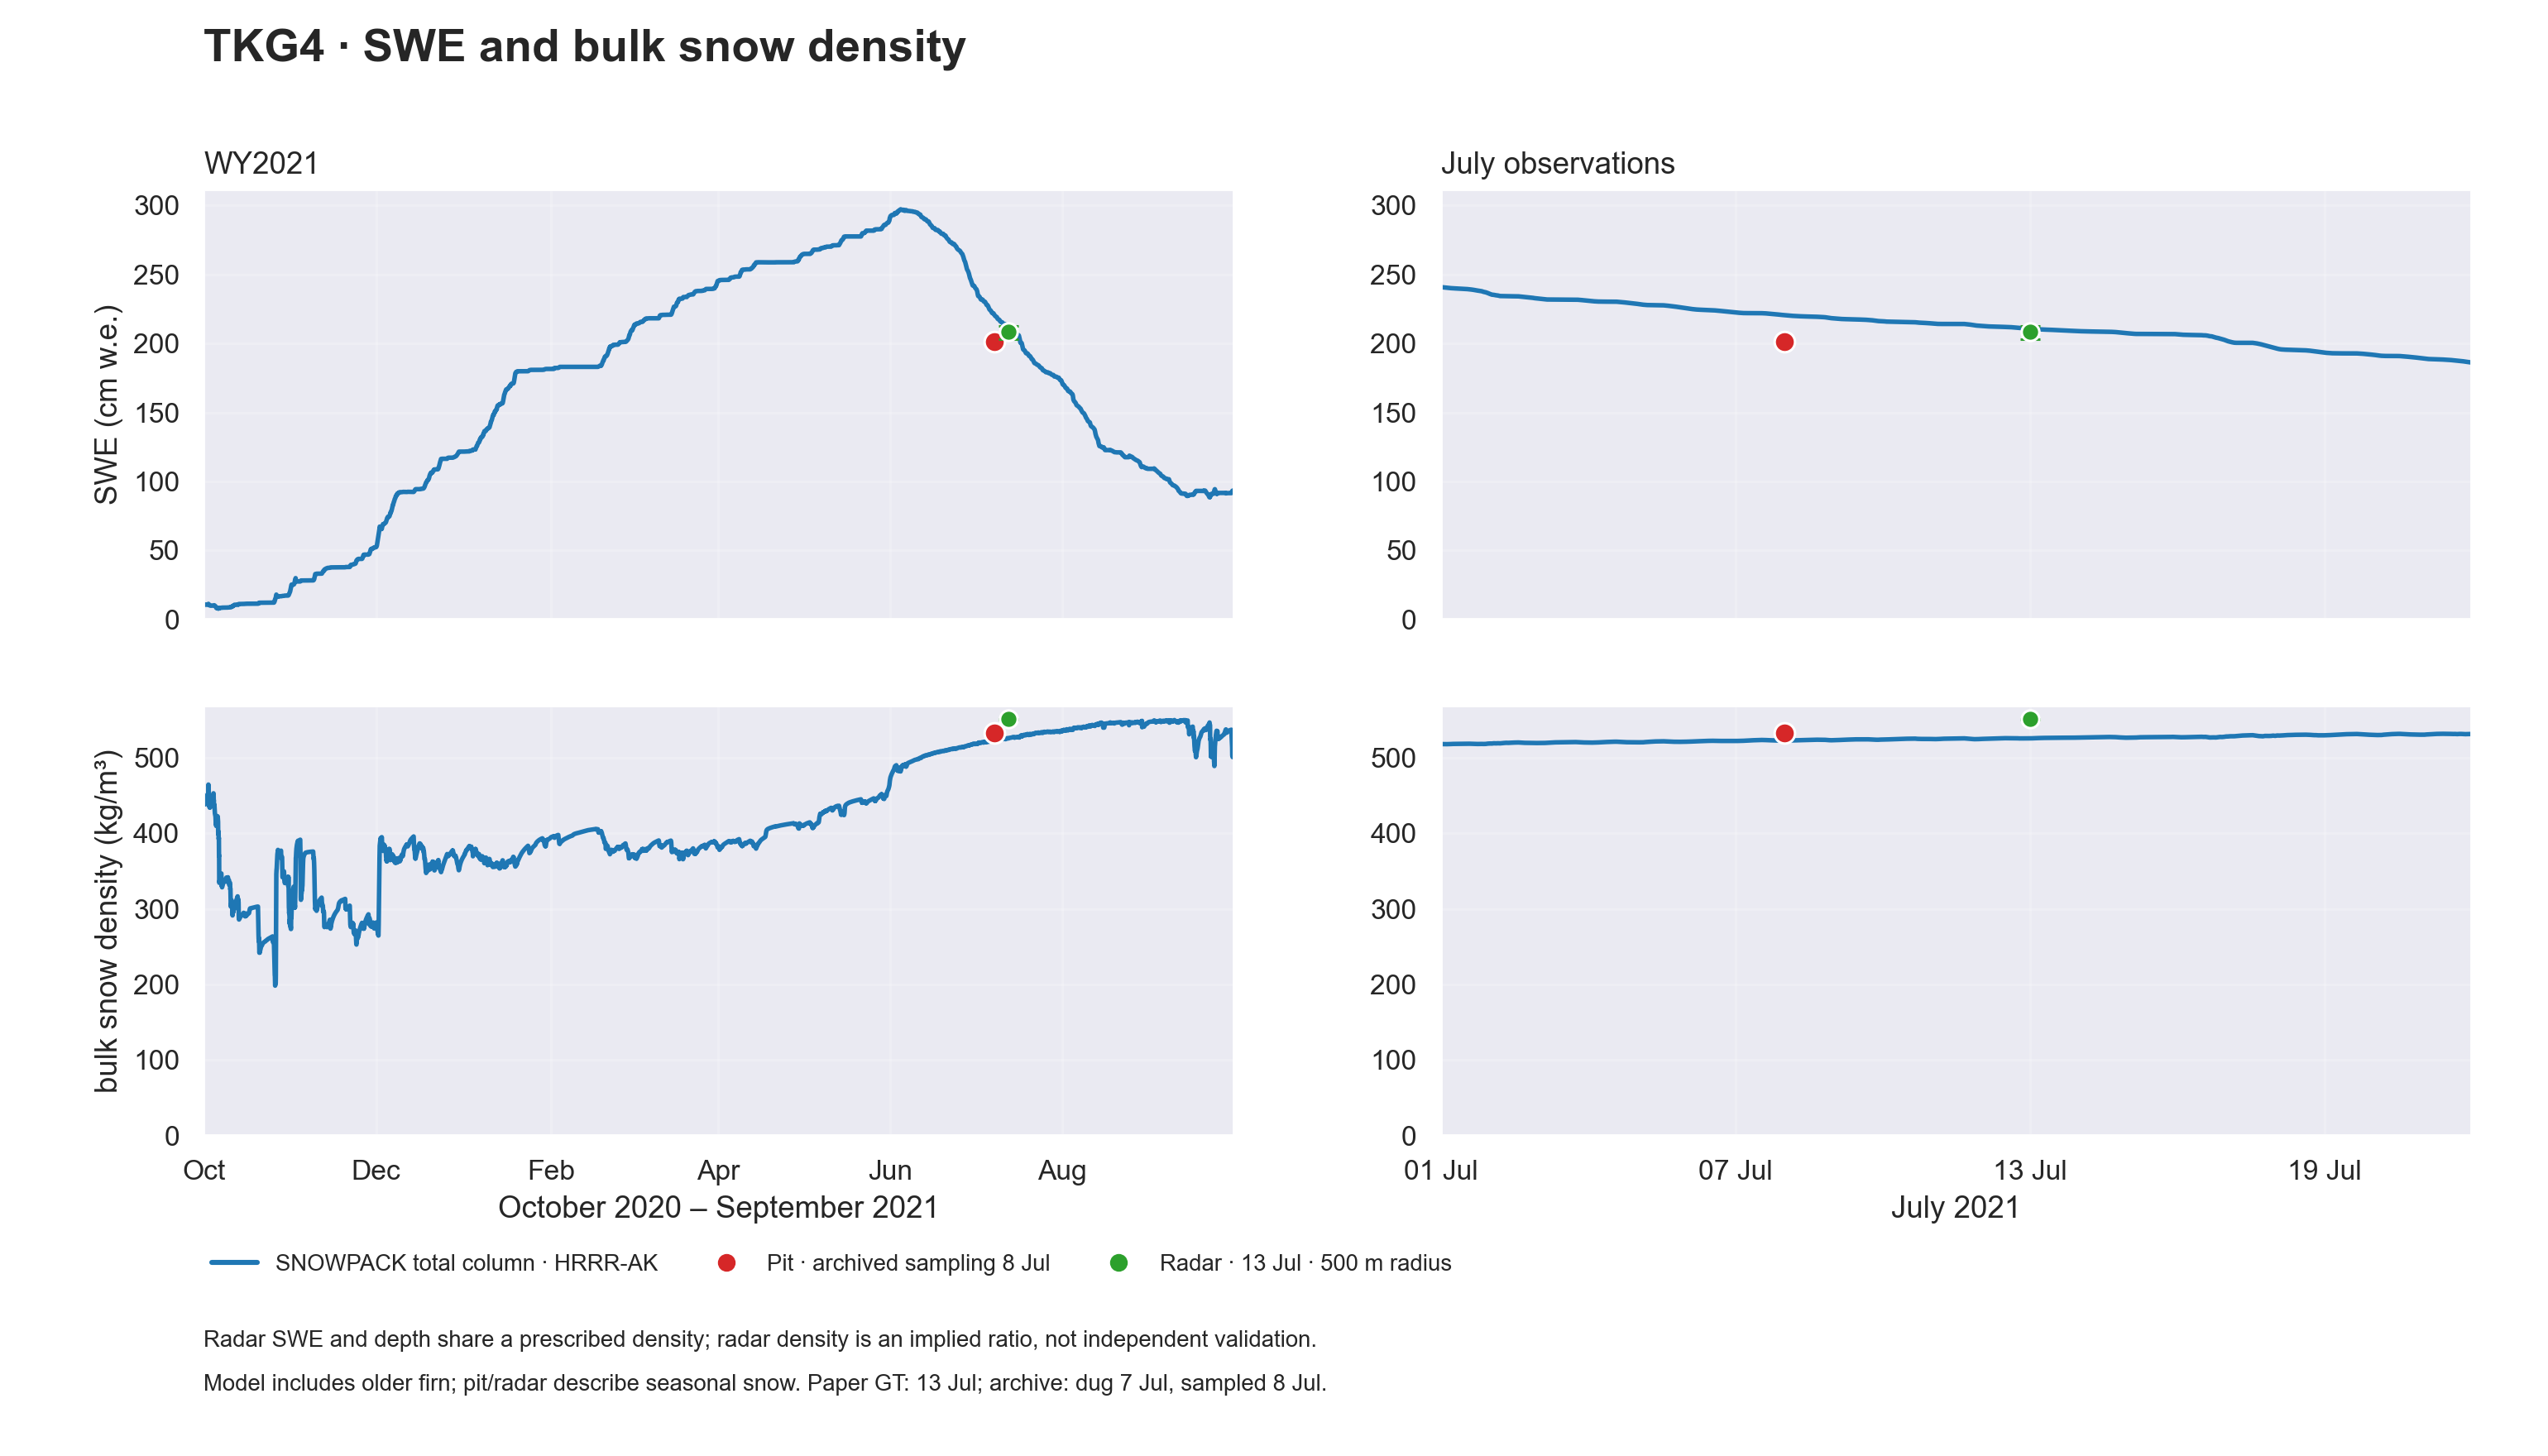

In [5]:
with sns.axes_style('darkgrid'), sns.plotting_context('notebook'):
    fig_comparison, axes = plt.subplots(2, 2, figsize=(14, 8), sharex='col')
    fig_comparison.subplots_adjust(left=0.08, right=0.97, top=0.87, bottom=0.22,
                                    hspace=0.20, wspace=0.20)
    metrics = [
        ('total_swe_m', 100, 'aa_swe_avg_m', 100, pit.seasonal_adjusted_swe_m*100, 'SWE (cm w.e.)'),
        ('bulk_density_kg_m3', 1, 'bulk_density_kg_m3', 1, pit.effective_bulk_density_kg_m3, 'bulk snow density (kg/m³)'),
    ]
    for row, (model_var, model_scale, radar_var, radar_scale, pit_value, label) in enumerate(metrics):
        for col in range(2):
            ax = axes[row, col]
            for i, (name, frame) in enumerate(models.items()):
                ax.plot(frame.index, frame[model_var]*model_scale,
                         color=sns.color_palette('tab10')[i], lw=1.8)
            ax.scatter(pit.sample_date, pit_value, color=PIT_COLOR, s=65,
                        edgecolor='white', marker='o', zorder=5)
            low, median, high = (local[radar_var]*radar_scale).quantile([0.1, 0.5, 0.9])
            ax.errorbar(mdates.date2num(RADAR_DATE), median,
                         yerr=np.array([[median-low], [high-median]]), fmt='o',
                         color=RADAR_COLOR, markeredgecolor='white', markersize=7,
                         capsize=4, elinewidth=1.5, zorder=5)
            ax.set_ylabel(label if col==0 else '')
            ax.set_ylim(bottom=0)
        # Identical y scales between the overview and July panels.
        ylim = (0, max(axes[row, 0].get_ylim()[1], axes[row, 1].get_ylim()[1]))
        for ax in axes[row]: ax.set_ylim(ylim)
    axes[0, 0].set_title('WY2021', loc='left')
    axes[0, 1].set_title('July observations', loc='left')
    axes[1, 0].set_xlim(START, END-pd.Timedelta(seconds=1))
    axes[1, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axes[1, 1].set_xlim(pd.Timestamp('2021-07-01'), pd.Timestamp('2021-07-22'))
    axes[1, 1].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 7, 13, 19]))
    axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    axes[1, 0].set_xlabel('October 2020 – September 2021')
    axes[1, 1].set_xlabel('July 2021')
    fig_comparison.suptitle('TKG4 · SWE and bulk snow density', x=0.08, ha='left', fontsize=18, weight='bold')
    handles = [Line2D([], [], color=MODEL_COLOR, lw=2, label='SNOWPACK total column · HRRR-AK'),
               Line2D([], [], marker='o', color=PIT_COLOR, ls='none', label='Pit · archived sampling 8 Jul'),
               Line2D([], [], marker='o', color=RADAR_COLOR, ls='none', label=f'Radar · 13 Jul · {RADAR_RADIUS_M:g} m radius')]
    fig_comparison.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.075, 0.11),
                           ncol=3, frameon=False, fontsize=9)
    fig_comparison.text(0.08, 0.075, 'Radar SWE and depth share a prescribed density; radar density is an implied ratio, not independent validation.', fontsize=9)
    fig_comparison.text(0.08, 0.045, 'Model includes older firn; pit/radar describe seasonal snow. Paper GT: 13 Jul; archive: dug 7 Jul, sampled 8 Jul.', fontsize=9)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for extension in ['png', 'pdf']:
            fig_comparison.savefig(FIGURE_DIR / f'tkg4_swe_bulk_density_WY2021.{extension}', dpi=220)
    plt.show()


## Date-matched comparison table

Model statistics use all finite hourly values on the corresponding UTC day: 8 July for archived pit SWE/density and 13 July for radar. For pit density this is an effective ratio using the reported seasonal depth and adjusted SWE, not a profile mean. Positive differences mean the model exceeds the supplied observation. These differences retain the total-column versus seasonal-column mismatch.

In [6]:
comparison_rows = []
for name, frame in models.items():
    for source, date in [('Pit', pit.sample_date), ('Radar', RADAR_DATE)]:
        day = frame.loc[(frame.index>=date) & (frame.index<date+pd.Timedelta(days=1))]
        for model_var, model_scale, radar_var, radar_scale, pit_value, label in metrics:
            values = day[model_var]*model_scale
            observed = pit_value if source=='Pit' else (local[radar_var]*radar_scale).median()
            comparison_rows.append({'run': name, 'source': source, 'date': date.date(), 'quantity': label,
                'observed': observed, 'model_mean': values.mean(), 'model_min': values.min(),
                'model_max': values.max(), 'model_hours': values.count(), 'model_minus_observed': values.mean()-observed,
                'radar_p10': (local[radar_var]*radar_scale).quantile(0.1) if source=='Radar' else np.nan,
                'radar_p90': (local[radar_var]*radar_scale).quantile(0.9) if source=='Radar' else np.nan})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(2))
print(comparison.round(2).to_string(index=False))
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(OUTPUT_DIR/'swe_density_comparison.csv', index=False)
    local.to_csv(OUTPUT_DIR/'radar_local_swe_density.csv', index=False)


                                                run  ... radar_p90
0  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...       NaN
1  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...       NaN
2  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...    212.84
3  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...    551.34

[4 rows x 12 columns]
                                             run source       date                  quantity  observed  model_mean  model_min  model_max  model_hours  model_minus_observed  radar_p10  radar_p90
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero    Pit 2021-07-08             SWE (cm w.e.)    201.43      219.48     218.28     220.47           24                 18.05        NaN        NaN
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero    Pit 2021-07-08 bulk snow density (kg/m³)    532.88      523.22     522.57     523.72           24                 -9.67        NaN        NaN
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  Radar 2021

run,source,date,quantity,observed,model_mean,model_min,model_max,model_hours,model_minus_observed,radar_p10,radar_p90
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,Pit,2021-07-08,SWE (cm w.e.),201.430,219.478,218.284,220.474,24,18.048,NaN,NaN
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,Pit,2021-07-08,bulk snow density (kg/m³),532.884,523.216,522.575,523.719,24,-9.668,NaN,NaN
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,Radar,2021-07-13,SWE (cm w.e.),208.167,209.741,208.939,210.554,24,1.574,202.797,212.841
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,Radar,2021-07-13,bulk snow density (kg/m³),550.861,526.181,525.530,526.515,24,-24.680,550.296,551.342


## Model layer profiles versus the archived pit

The `.pro` file contains element top heights (`0501`, cm above the model base), densities (`0502`, kg/m³), and ages (`0505`, days). Extract profiles on **8 July** (archived density sampling) and **13 July** (paper GT/GPR). Use **12:00 UTC as an illustrative snapshot**, not a known field sampling time; change `PROFILE_HOUR_UTC` to explore timing.

Convert model elevations to depth below the current surface. Check reconstructed total thickness and integrated density × thickness against the concurrent SMET depth/SWE before comparing profiles. These exports use positive top heights, no soil, and a base at zero; the parser rejects other geometries instead of guessing.

Pit density depths are preserved as recorded. Irregular entries (350 cm with length 13 cm, followed by 363 cm) suggest that recorded depths may be interval tops, but the sheet does not explicitly define the convention. Plot samples at their **recorded depth**, without inventing interval boundaries or integrating the pit profile. The 378 cm seasonal/firn horizon comes from the field notes. Radar contributes a bulk-density reference only, not a vertical profile.

In [7]:
PROFILE_HOUR_UTC = 12
PROFILE_DATES = [pit.sample_date, RADAR_DATE]
PROFILE_TARGETS = [date + pd.Timedelta(hours=PROFILE_HOUR_UTC) for date in PROFILE_DATES]
PROFILE_TIME_TOLERANCE = pd.Timedelta('1h')
SEASON_START = pd.Timestamp('2020-10-01')

def read_selected_pro(path, targets, tolerance):
    """Stream only relevant dated blocks, retaining required arrays and header metadata."""
    blocks, declarations, station = {}, {}, {}
    section, stamp, block = None, None, {}
    def store():
        if stamp is not None and min(abs(stamp-t) for t in targets) <= tolerance:
            if stamp in blocks:
                raise ValueError(f'Duplicate profile timestamp: {stamp}')
            blocks[stamp] = block.copy()
    with path.open() as stream:
        for line in stream:
            line = line.strip()
            if line.startswith('['):
                section = line
                continue
            if section == '[STATION_PARAMETERS]' and '=' in line:
                key, value = line.split('=', 1)
                station[key.strip()] = value.strip()
            elif section == '[HEADER]' and line[:4] in ['0501', '0502', '0505', '0519']:
                declarations[line[:4]] = line
            elif section == '[DATA]':
                parts = line.split(',')
                if parts[0] == '0500':
                    store()
                    stamp = pd.to_datetime(parts[1], format='%d.%m.%Y %H:%M:%S')
                    block = {}
                    if stamp > max(targets)+tolerance:
                        break
                elif parts[0] in ['0501', '0502', '0505', '0519'] and stamp is not None:
                    if min(abs(stamp-t) for t in targets) <= tolerance:
                        count = int(parts[1])
                        values = np.asarray(parts[2:], dtype=float)
                        if len(values) != count:
                            raise ValueError(f'Array count mismatch: {path}, {stamp}, {parts[0]}')
                        block[parts[0]] = values
        else:
            store()
    return blocks, declarations, station

layer_profiles, profile_rows, profile_files = {}, [], []
for run in models:
    smet_path = Path(model_audit.loc[model_audit.run.eq(run), 'path'].iloc[0])
    pro_path = smet_path.with_suffix('.pro')
    if not pro_path.is_file():
        raise FileNotFoundError(pro_path)
    # SMET tz is authoritative for comparing model timestamps in this paired output.
    tz_offset = pd.Timedelta(hours=float(model_headers[run]['tz']))
    local_targets = [t+tz_offset for t in PROFILE_TARGETS]
    blocks, declarations, station = read_selected_pro(pro_path, local_targets, PROFILE_TIME_TOLERANCE)
    print(pro_path)
    print('Profile field declarations:', declarations)
    profile_files.append(str(pro_path))
    for target in PROFILE_TARGETS:
        if not blocks:
            raise ValueError(f'No profile within tolerance for {target}')
        local_time = min(blocks, key=lambda stamp: abs((stamp-tz_offset)-target))
        actual = local_time-tz_offset
        if abs(actual-target)>PROFILE_TIME_TOLERANCE:
            raise ValueError(f'No profile within tolerance for {target}')
        block = blocks[local_time]
        heights, density, age, soil = [block[key] for key in ['0501', '0502', '0505', '0519']]
        if not (len(heights)==len(density)==len(age)==len(soil)):
            raise ValueError('Profile fields have different element counts.')
        if not (np.isfinite(heights).all() and np.isfinite(density).all() and np.isfinite(age).all()):
            raise ValueError('Nonfinite layer values.')
        if not ((heights>0).all() and (np.diff(heights)>0).all() and (density>0).all() and (soil==0).all()):
            raise ValueError('Expected positive increasing snow tops, positive density, and no soil.')
        bottom = np.r_[0, heights[:-1]]
        thickness_m = (heights-bottom)/100
        surface_cm = heights[-1]
        layers = pd.DataFrame({'height_top_cm': heights, 'height_bottom_cm': bottom,
            'depth_top_cm': surface_cm-heights, 'depth_bottom_cm': surface_cm-bottom,
            'thickness_m': thickness_m, 'density_kg_m3': density, 'age_days': age})
        layers['swe_cm'] = density * thickness_m / 10
        layers['estimated_origin_UTC'] = actual-pd.to_timedelta(age, unit='D')
        layers['origin_in_WY2021'] = layers.estimated_origin_UTC.ge(SEASON_START)
        # Element age can be averaged during model merging: this is a diagnostic classification.
        layer_profiles[(run, actual)] = layers
        concurrent = full_models[run].loc[actual]
        reconstructed_swe_cm = layers.swe_cm.sum()
        depth_difference_cm = surface_cm-concurrent.total_depth_m*100
        swe_difference_cm = reconstructed_swe_cm-concurrent.total_swe_m*100
        if abs(depth_difference_cm)>0.1 or abs(swe_difference_cm)>0.5:
            raise ValueError(f'Profile/SMET consistency failed: depth {depth_difference_cm:.3f} cm, SWE {swe_difference_cm:.3f} cm')
        young = layers.loc[layers.origin_in_WY2021]
        old = layers.loc[~layers.origin_in_WY2021]
        # Verify that age-classified older layers are at the bottom, if a horizon is drawn.
        flags = layers.origin_in_WY2021.to_numpy()
        contiguous = not (np.diff(flags.astype(int))<0).any()
        horizon_cm = young.depth_bottom_cm.max() if contiguous and not young.empty and not old.empty else np.nan
        profile_rows.append({'run': run, 'requested_UTC': target, 'profile_UTC': actual,
            'layers': len(layers), 'total_depth_cm': surface_cm,
            'integrated_swe_cm': reconstructed_swe_cm,
            'depth_minus_smet_cm': depth_difference_cm, 'swe_minus_smet_cm': swe_difference_cm,
            'age_classified_seasonal_depth_cm': young.thickness_m.sum()*100,
            'age_classified_seasonal_swe_cm': young.swe_cm.sum(),
            'age_classified_seasonal_density_kg_m3': (young.density_kg_m3*young.thickness_m).sum()/young.thickness_m.sum() if not young.empty else np.nan,
            'older_layer_depth_cm': old.thickness_m.sum()*100,
            'age_horizon_depth_cm': horizon_cm, 'age_classes_contiguous': contiguous})
profile_audit = pd.DataFrame(profile_rows)
display(profile_audit.round(3))
print(profile_audit.round(3).to_string(index=False))


/home/cassie/python/models/run_snowpack/sites/tkg4/output/hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero.pro
Profile field declarations: {'0501': '0501,nElems,height [> 0: top, < 0: bottom of elem.] (cm)', '0502': '0502,nElems,element density (kg m-3)', '0505': '0505,nElems,element age (days)', '0519': '0519,nElems,soil volume fraction (%)'}
                                                run  ... age_classes_contiguous
0  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...                   True
1  hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero  ...                   True

[2 rows x 14 columns]
                                             run       requested_UTC         profile_UTC  layers  total_depth_cm  integrated_swe_cm  depth_minus_smet_cm  swe_minus_smet_cm  age_classified_seasonal_depth_cm  age_classified_seasonal_swe_cm  age_classified_seasonal_density_kg_m3  older_layer_depth_cm  age_horizon_depth_cm  age_classes_contiguous
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_ze

run,requested_UTC,profile_UTC,layers,total_depth_cm,integrated_swe_cm,depth_minus_smet_cm,swe_minus_smet_cm,age_classified_seasonal_depth_cm,age_classified_seasonal_swe_cm,age_classified_seasonal_density_kg_m3,older_layer_depth_cm,age_horizon_depth_cm,age_classes_contiguous
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,2021-07-08 12:00:00,2021-07-08 12:00:00,707,419.23,219.467,-0.003,-0.000,404.26,210.136,519.803,14.97,404.26,True
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,2021-07-13 12:00:00,2021-07-13 12:00:00,673,398.50,209.744,0.004,0.002,383.53,200.408,522.536,14.97,383.53,True


### Density versus depth below surface

Solid blue: native model element densities; red circles: archived pit samples at their recorded depths. The pit's 378 cm seasonal horizon is the red dashed line. Where element ages yield a contiguous boundary, an orange dashed line marks the **age-classified** 2020/21 horizon. Layer ages may be averaged when elements merge, so this is diagnostic rather than an exact tracer of deposition year.

The July 13 panel reuses the July 8 archived pit profile for timing context; it is **not a second pit measurement**. The green vertical reference on July 13 is the radar-implied bulk density. It has no layer information. Material below the model base has no simulated counterpart even if the pit extends deeper.

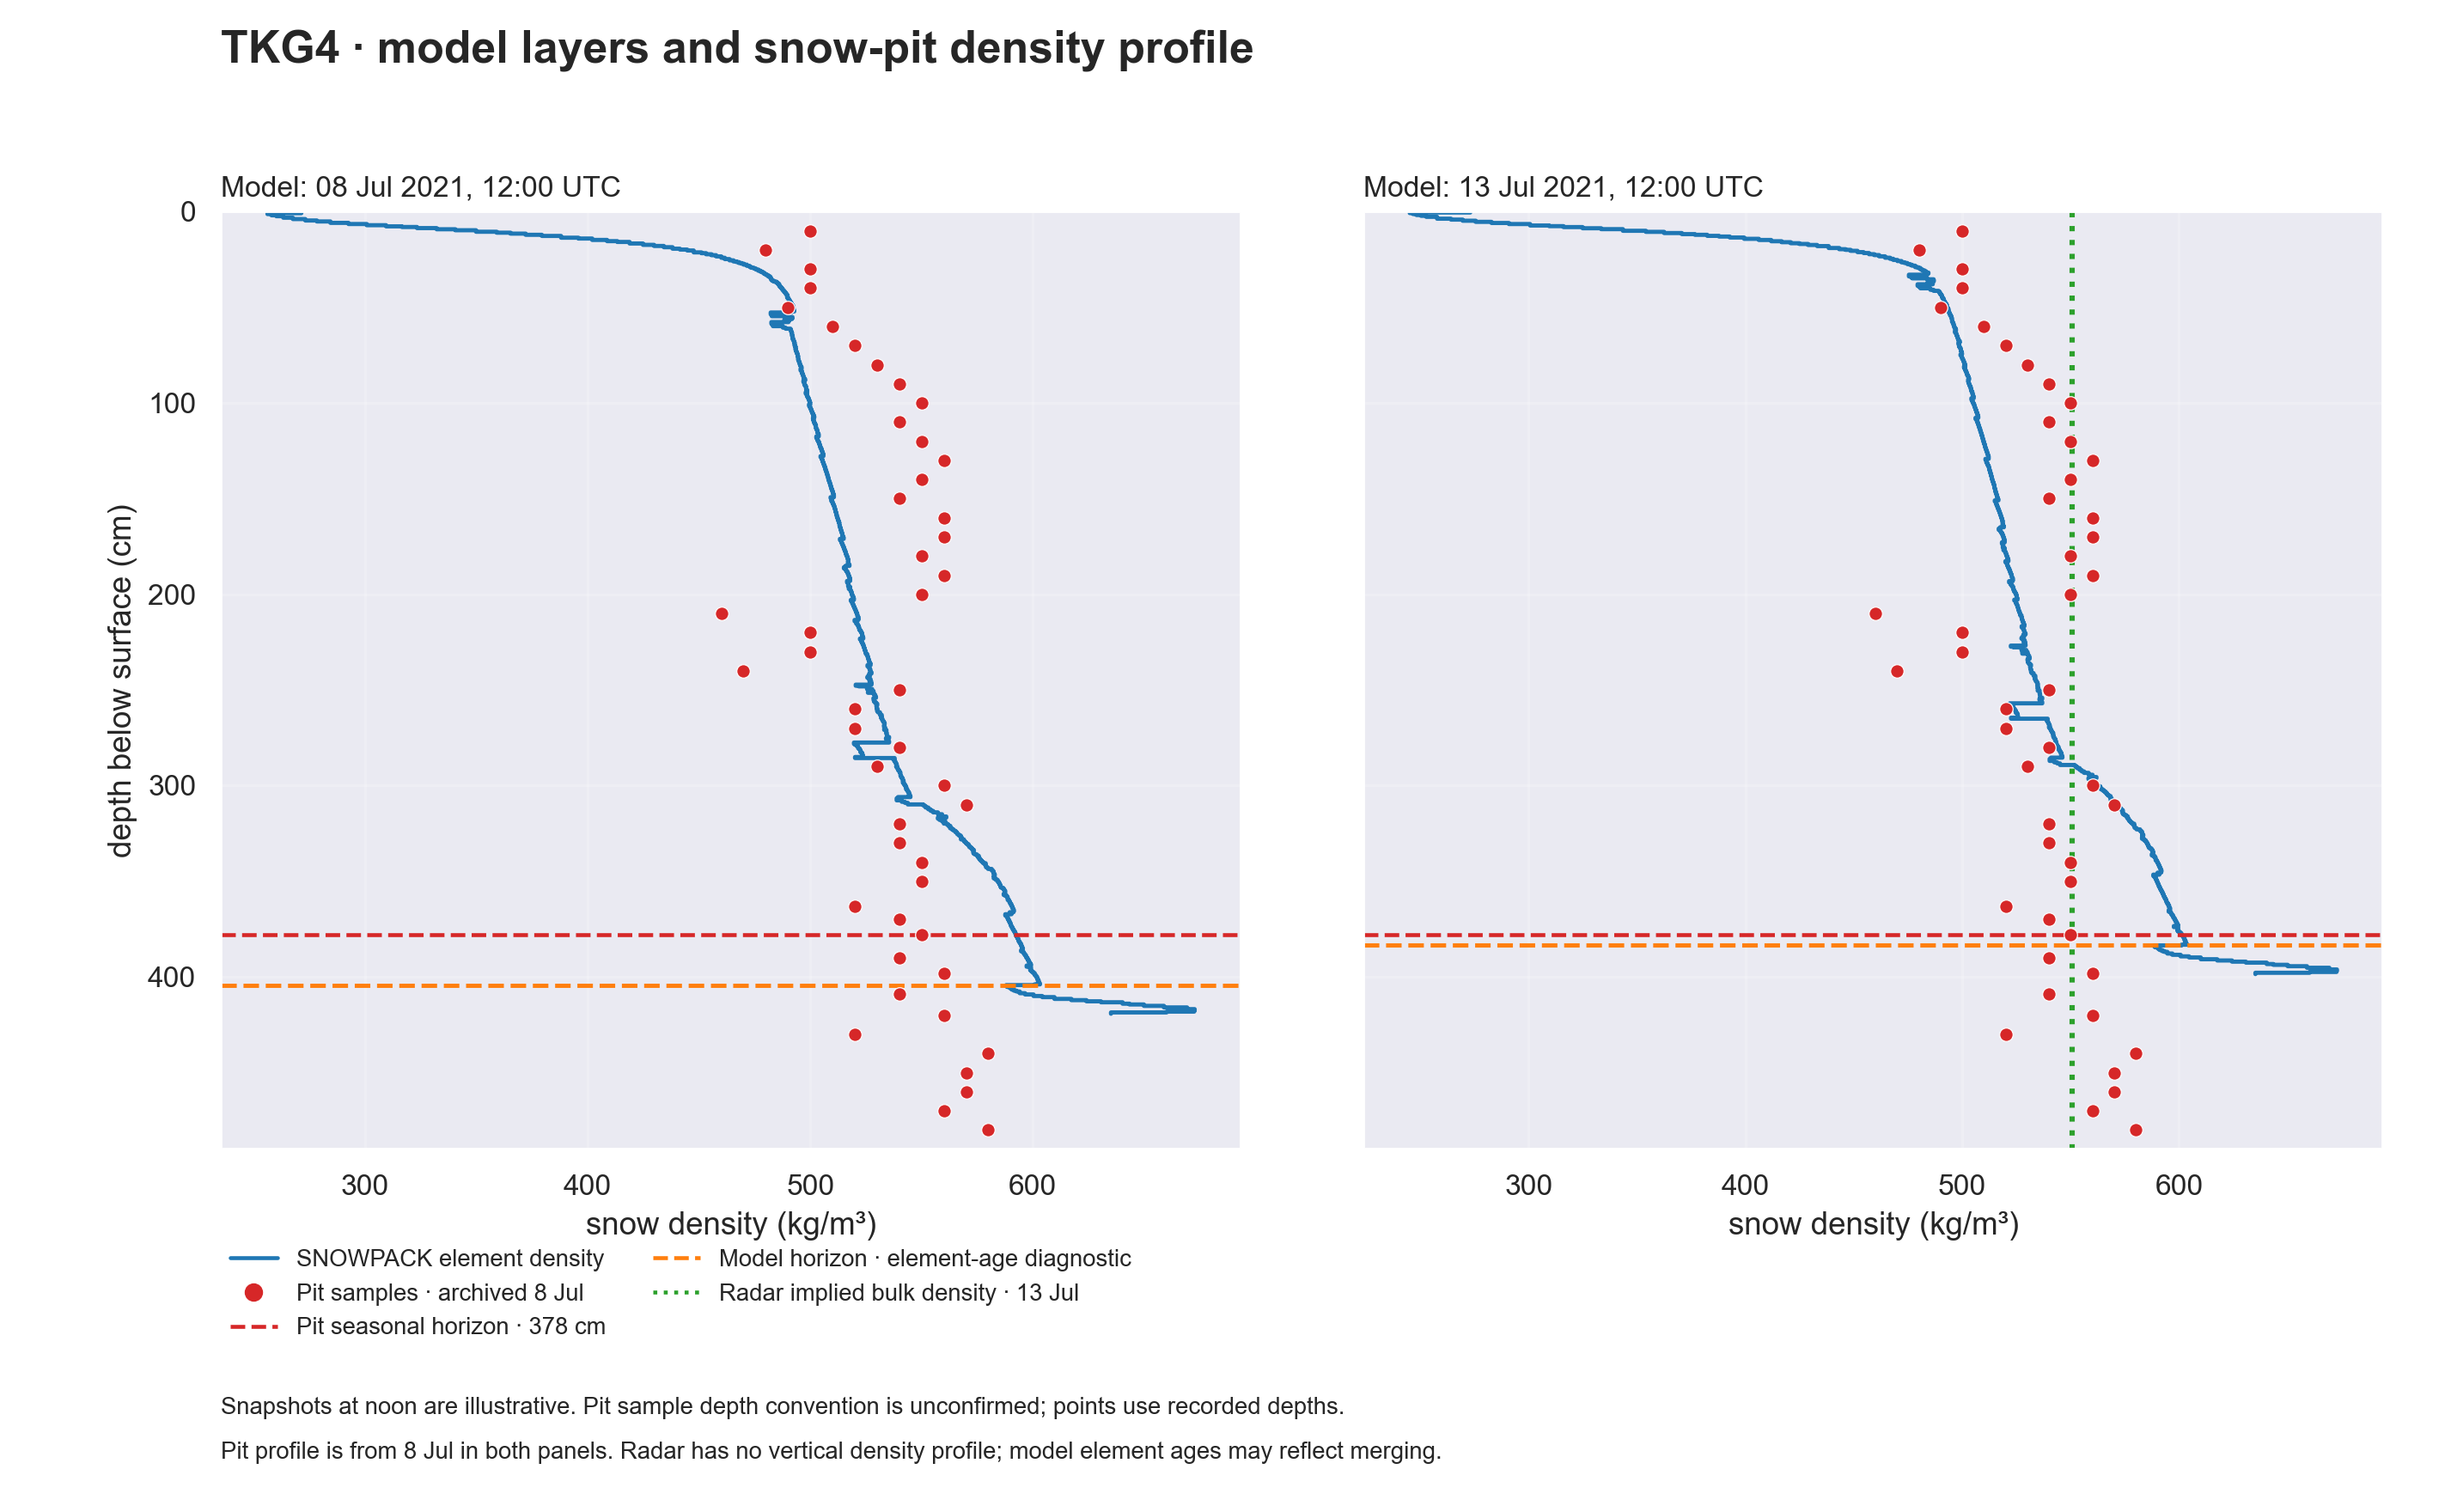

In [8]:
with sns.axes_style('darkgrid'), sns.plotting_context('notebook'):
    fig_profiles, profile_axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
    fig_profiles.subplots_adjust(left=0.09, right=0.97, top=0.86, bottom=0.24, wspace=0.12)
    maximum_depth = max(pit_profile.depth_cm.max(), profile_audit.total_depth_cm.max())
    for col, target in enumerate(PROFILE_TARGETS):
        ax = profile_axes[col]
        for run in models:
            row = profile_audit.loc[profile_audit.run.eq(run) & profile_audit.requested_UTC.eq(target)].iloc[0]
            layers = layer_profiles[(run, row.profile_UTC)].sort_values('depth_top_cm')
            # Staircase along actual element boundaries; no smoothing or vertical stretching.
            x = np.repeat(layers.density_kg_m3.to_numpy(), 2)
            y = np.column_stack([layers.depth_top_cm, layers.depth_bottom_cm]).ravel()
            ax.plot(x, y, color=MODEL_COLOR, lw=1.6)
            if np.isfinite(row.age_horizon_depth_cm):
                ax.axhline(row.age_horizon_depth_cm, color='tab:orange', ls='--', lw=1.6)
        ax.scatter(pit_profile.density_g_cm3*1000, pit_profile.depth_cm,
                    color=PIT_COLOR, s=26, edgecolor='white', linewidth=0.4, zorder=5)
        ax.axhline(pit.seasonal_depth_m*100, color=PIT_COLOR, ls='--', lw=1.5)
        if target.normalize()==RADAR_DATE:
            ax.axvline(local.bulk_density_kg_m3.median(), color=RADAR_COLOR, ls=':', lw=2)
        ax.set_title(f'Model: {target:%d %b %Y, %H:%M} UTC', loc='left', fontsize=11)
        ax.set_xlabel('snow density (kg/m³)')
        ax.set_ylim(maximum_depth+10, 0)
    profile_axes[0].set_ylabel('depth below surface (cm)')
    fig_profiles.suptitle('TKG4 · model layers and snow-pit density profile', x=0.09, ha='left', fontsize=17, weight='bold')
    handles = [Line2D([], [], color=MODEL_COLOR, label='SNOWPACK element density'),
               Line2D([], [], marker='o', color=PIT_COLOR, ls='none', label='Pit samples · archived 8 Jul'),
               Line2D([], [], color=PIT_COLOR, ls='--', label='Pit seasonal horizon · 378 cm'),
               Line2D([], [], color='tab:orange', ls='--', label='Model horizon · element-age diagnostic'),
               Line2D([], [], color=RADAR_COLOR, ls=':', label='Radar implied bulk density · 13 Jul')]
    fig_profiles.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.085, 0.10),
                         ncol=2, frameon=False, fontsize=9)
    fig_profiles.text(0.09, 0.065, 'Snapshots at noon are illustrative. Pit sample depth convention is unconfirmed; points use recorded depths.', fontsize=9)
    fig_profiles.text(0.09, 0.035, 'Pit profile is from 8 Jul in both panels. Radar has no vertical density profile; model element ages may reflect merging.', fontsize=9)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for extension in ['png', 'pdf']:
            fig_profiles.savefig(FIGURE_DIR/f'tkg4_layer_density_profiles_July2021.{extension}', dpi=220)
    plt.show()
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    profile_audit.to_csv(OUTPUT_DIR/'layer_profile_audit.csv', index=False)
    for (run, time), layers in layer_profiles.items():
        layers.to_csv(OUTPUT_DIR/f'{run}_layers_{time:%Y%m%dT%H%M}.csv', index=False)


## What to investigate next

- Review the element-age horizon against layer IDs/deposition history before treating age-classified seasonal SWE as a definitive seasonal tracer.
- Resolve the paper GT date versus archived dig/sample dates and add the paper citation supplied for radar timing.
- Confirm radar prescribed density and whether pit densities informed the radar product before treating either as independent validation.
- Review the pit's adjusted SWE calculation and sample interval conventions before integrating the density profile; the archived profile includes firn below 378 cm.

The autumn depth subtraction in the snow-depth notebook is an illustrative geometric adjustment. Applying that depth offset to density or SWE without corresponding firn mass would mix incompatible quantities.